<a href="https://colab.research.google.com/github/Atin2001/GCI/blob/main/GCI2026W_%E7%AC%AC5%E5%9B%9E_Python%E3%81%AB%E3%82%88%E3%82%8B%E3%83%86%E3%82%99%E3%83%BC%E3%82%BF%E5%8F%AF%E8%A6%96%E5%8C%96%E3%81%AE%E5%9F%BA%E7%A4%8E%EF%BC%88Matplotlib%EF%BC%89_%E8%A7%A3%E7%AD%94.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 第5回 1 練習と総合問題解答

In [ ]:
# 以下のライブラリを使うので、あらかじめ読み込んでおいてください
import numpy as np
import numpy.random as random
import scipy as sp
import pandas as pd
from pandas import Series,DataFrame
import os
import zipfile
import requests
import io

# 可視化ライブラリ
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
%matplotlib inline

# 小数第3位まで表示
%precision 3

'%.3f'

#### <練習問題 1-1>

$y = 5x + 3$ （$x$は$-10$から$10$の値）のグラフを描いてみましょう。

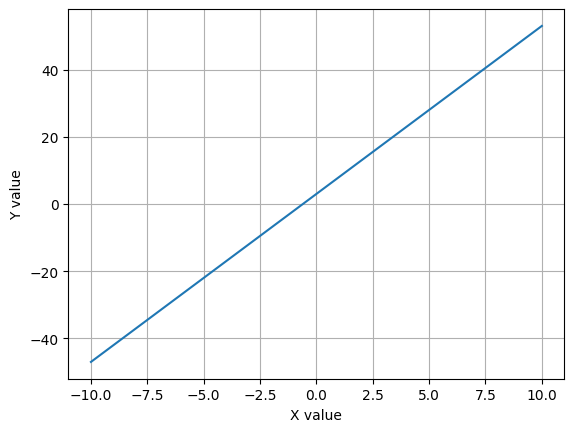

In [ ]:
x = np.linspace(-10, 10,100)
plt.plot(x, 5*x + 3)
plt.xlabel("X value")
plt.ylabel("Y value")
plt.grid(True)

#### <練習問題 1-2>

「$y = sin(x)$」と「$y = cos(x)$」のグラフを重ねて描いてください（$x$は-10から10の値）

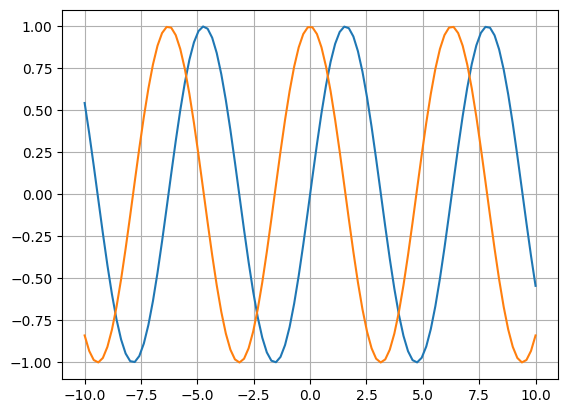

In [ ]:
# 解答
x = np.linspace(-10, 10,100)
plt.plot(x, np.sin(x))
plt.plot(x, np.cos(x))

plt.grid(True)

#### <練習問題 1-3>

0から1の値をとる一様乱数を1,000個、2組発生させて、それぞれのヒストグラムを描いてみましょう。

なお、それぞれのヒストグラムを別のグラフに表示するために、`plt.subplot`を利用してください。また、ここで一様乱数とは、ある数から別のある数まで等確率で発生する乱数のことをいい、`np.random.uniform`を使います。たとえば、0から1までの数を10個発生させる場合は、`np.random.uniform(0.0, 1.0, 10)`とします。

また、1,000個だけではなく、100個や10,000個などでも実施してみましょう。何かわかることはありますか。

In [ ]:
# 解答
import math

# 解答
def uni_hist(N):
    # 一様乱数の発生
    x = np.random.uniform(0.0, 1.0, N)
    y = np.random.uniform(0.0, 1.0, N)

    plt.subplot(2, 1, 1)
    plt.hist(x)
    plt.title("No1:histogram")

    plt.subplot(2, 1, 2)
    plt.hist(y)
    plt.title("No2:histogram")

    plt.grid(True)

    #タイトルの被りを防ぐ
    plt.tight_layout()

uni_hist(1000)

#### 100個の一様乱数を2組発生させる場合のプログラム

In [ ]:
# N=100
uni_hist(100)

#### 10,000個の一様乱数を2組発生させる場合のプログラム

In [ ]:
# N = 10000
uni_hist(10000)

なお、2組の一様乱数は、Nが大きくなるにつれ、棒グラフにばらつきがなくなり、一定になっているのがわかります。

#### おまけ問題

乱数を発生させる方法を使って、円周率を求めるプログラムを作成してみましょう。なお、このアプローチを**モンテカルロ法**といいます。

（1）区間`[0,1)`上の一様分布に従う乱数を2組発生させて、それぞれ10,000個の一様乱数を作ってみましょう。なお、一様乱数とは、ある数から数まで等確率で発生する乱数のことをいい、`np.random.uniform`を使います。使い方としては、0から1までの数を10個発生させる場合は、`np.random.uniform(0.0, 1.0, 10)`とします。

In [ ]:
# 解答
import math

# 解答 (1)
N = 10000

# 一様乱数の発生
x = np.random.uniform(0.0, 1.0, N)
y = np.random.uniform(0.0, 1.0, N)

（2）$x−y$軸を使った中心$(0,0)$、半径1の円と、長さ1の正方形を考えたとき、円の面積は$\pi$となり、正方形の面積は1となります。先ほどの$x$と$y$の組み合わせの乱数10,000個のうち、この円の内部に入る点は何組あるでしょうか。

ここで、円の内部に入るとは、$x−y$座標の原点から点$ (x, y) $のベクトルの長さを求め、それが1より小さくなる場合を判定基準とします。なお、その長さを求めるために、ユークリッドノルム($\sqrt{x^2 + y^2}$)を使い、 `math.hypot(x,y)`で計算できます。さらに、余裕があれば、円の中に入った$x$と$y$の組み合わせと外に出た$x$と$y$の組み合わせをプロットして図にしてみましょう。

In [ ]:
# 円の中に入ったxとy
inside_x = []
inside_y = []

# 円の外に出たxとy
outside_x = []
outside_y = []

count_inside = 0
for count in range(0, N):
    d = math.hypot(x[count], y[count])
    if d < 1:
        count_inside += 1
        # 円の内部に入った時のxとyの組み合わせ
        # appendはリストに要素を追加するメソッド
        inside_x.append(x[count])
        inside_y.append(y[count])
    else:
        # 円の外に出た時のxとyの組み合わせ
        outside_x.append(x[count])
        outside_y.append(y[count])

print("円の内部に入った数:", count_inside)

In [ ]:
# さらに図にする
# 図のサイズ
plt.figure(figsize=(5, 5))

# 円を描くためのデータ
circle_x = np.arange(0,1, 0.001)
circle_y = np.sqrt(1 - circle_x * circle_x)

# 円を描く
plt.plot(circle_x, circle_y)

# 円の中に入っているのが、red
plt.scatter(inside_x, inside_y, color="r")
# 円の外に出たのが、blue
plt.scatter(outside_x, outside_y, color="b")

plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

In [ ]:
# (別解)

# ランダムに生成した各点(x, y)の、原点(0, 0)からのユークリッド距離を算出
r = np.sqrt(x ** 2 + y ** 2)

# 円を描く
plt.figure(figsize=(5, 5))
plt.plot(circle_x, circle_y)

# 円の中に入っているのが、red
plt.scatter(x[r <= 1], y[r <= 1], color="r")
# 円の外に出たのが、blue
plt.scatter(x[r > 1], y[r > 1], color="b")

plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)

（3）半径1の1/4の円の面積と長さ1の正方形の面積の比は、$ \pi /4 : 1$となります。これと（2）の結果を利用して、円周率を求めてみましょう。

In [ ]:
# 解答 (3)
print("円周率の近似値:",4.0 * count_inside / N)

# (別解)
print("別解:", (r <= 1).sum() / 10000 * 4)

#### <練習問題 1-4>

数学の成績を示すデータである「student-mat.csv」を使って、学校を選んだ理由（`reason`）を円グラフ化して、それぞれの割合を出してください。[データセット1]

In [ ]:
# データがあるurlの指定 [データセット1]
url = 'https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC5%E5%9B%9E/student.zip'

# データをurlから取得
r = requests.get(url, stream=True)

# zipfile内のstudent-mat.csvをカレントディレクトリ内のdataディレクトリに展開
with zipfile.ZipFile(io.BytesIO(r.content)) as existing_zip:
    existing_zip.extract('student-mat.csv', 'data')

# csvfileが存在するディレクトリ
data_dir = './data'

# data_dir内のファイルを確認
os.listdir(data_dir)

# student-mat.csvのpathを取得
path = os.path.join(data_dir, 'student-mat.csv')

In [ ]:
# 解答
student_data_math = pd.read_csv(path, sep=';')
student_data_math.groupby('reason').size().plot(kind='pie', autopct='%1.1f%%',startangle=90)
plt.ylabel('')
plt.axis('equal')

#### <練習問題 1-5>

上記と同じデータで、`higher` (高い教育を受けたいかどうか。値は`yes`か`no`）を軸にして、それぞれの数学の最終成績`G3`の平均値を棒グラフで表示してください。ここから何か推測できることはありますか？

In [ ]:
# 解答
student_data_math.groupby('higher')['G3'].mean().plot(kind='bar')
plt.xlabel('higher')
plt.ylabel('G3 grade avg')

# 高い教育を受けた人たちの方が成績は高めであることがわかる

#### <練習問題 1-6>

上記と同じデータで、通学時間（`traveltime`）を軸にして、それぞれの数学の最終成績`G3`の平均値を横棒グラフで表示してください。何か推測できることはありますか？

In [ ]:
# 解答
student_data_math.groupby(['traveltime'])['G3'].mean().plot(kind='barh')
plt.xlabel('G3 Grade avg')

# 通学時間が長いと成績が低くなる傾向にある

## 1.5 総合問題

### ■総合問題1-1 時系列データ分析

ここでは、本章で身に付けたpandasやscipyなどを使って、時系列データついて扱っていきましょう。

（1）（データの取得と確認）下記のサイトより、dow_jones_index.zipをダウンロードし、含まれている`dow_jones_index.data`を使って、データを読み込み、はじめの5行を表示してください。またデータのそれぞれのカラム情報等を見て、`NaN`などがあるか確認してください。

https://archive.ics.uci.edu/ml/machine-learning-databases/00312/dow_jones_index.zip [データセット2]

In [ ]:
# 解答 (1)
# データの取得
import requests, zipfile
from io import StringIO
import io

# url　※アクセス集中負荷の観点から、松尾研AWSリンクを使用
zip_file_url = 'https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC5%E5%9B%9E/dow_jones_index.zip'
r = requests.get(zip_file_url, stream=True)
z = zipfile.ZipFile(io.BytesIO(r.content))
# 展開
z.extractall()

In [ ]:
# データの読み込み
dow_jones_index = pd.read_csv('dow_jones_index.data',sep=',')

In [ ]:
# 先頭5行の確認
dow_jones_index.head()

In [ ]:
# データのカラム情報
dow_jones_index.info()

（2）（データの加工）カラムの`open`、`high`、`low`、`close`等のデータは数字の前に$マークが付いているため、これを取り除いてください。また、日時を`date`型で読み込んでいない場合は、date型に変換しましょう。

In [ ]:
# 解答 (2)
# 型変更　日時型
dow_jones_index.date = pd.to_datetime(dow_jones_index.date)

# ＄マークを消す
delete_dolchar = lambda x: str(x).replace('$', '')

# 対象は、open,high,low.close,next_weeks_open,next_weeks_close
# 文字型を数値型を変換する処理
dow_jones_index.open = pd.to_numeric(dow_jones_index.open.map(delete_dolchar))
dow_jones_index.high = pd.to_numeric(dow_jones_index.high.map(delete_dolchar))
dow_jones_index.low = pd.to_numeric(dow_jones_index.low.map(delete_dolchar))
dow_jones_index.close = pd.to_numeric(dow_jones_index.close.map(delete_dolchar))
dow_jones_index.next_weeks_open = pd.to_numeric(dow_jones_index.next_weeks_open.map(delete_dolchar))
dow_jones_index.next_weeks_close = pd.to_numeric(dow_jones_index.next_weeks_close.map(delete_dolchar))

In [ ]:
# 再確認
dow_jones_index.head()

（3）カラムの`close`について、各`stock`ごとの要約統計量を算出してください。

In [ ]:
# 解答(3)
# indexをセットする
dow_jones_index_stock_index = dow_jones_index.set_index(['date','stock'])

# データフレームワークの再構成
dow_jones_index_stock_index_unstack = dow_jones_index_stock_index.unstack()

# closeのみ対象
dow_close_data = dow_jones_index_stock_index_unstack['close']

#　要約統計量
dow_close_data.describe()

（4）カラムの`close`について、各`stock`の相関を算出する相関行列を出してください。また、`Seaborn`の`heatmap`関数を使って、相関行列のヒートマップを描いてみましょう（ヒント：`Pandas`の`corr`メソッドを使います）。

In [ ]:
# 解答(4)
# 相関行列
corr_data = dow_close_data.corr()
corr_data

（4 続き）また、`seaborn`の`heatmap`を使って、相関行列のヒートマップを描いてみましょう（ヒント：`pandas`の`corr()`を使います）。

In [ ]:
# 解答(4)
# ヒートマップ
sns.heatmap(corr_data)

（5）(4)で算出した相関行列の中で一番相関係数が高い`stock`の組み合わせを抽出してください。さらに、その中でもっとも相関係数が高いペアを抜き出し、それぞれの時系列グラフを描いてください。

In [ ]:
# 解答(5)
# 相関係数が最大となるペアの抽出（自分自身以外の29ペアの中で）

# initial value
max_corr = 0
stock_1 = ''
stock_2 = ''

for i in range(len(corr_data)):

    # 相関係数を降順に並べ、自分自身を除いた最大値を取得
    sorted_corr = corr_data.iloc[i:i+1].unstack().sort_values(ascending=False)

    # 2番目の要素（自分自身以外の最大相関）
    corr_value = sorted_corr.iloc[1]
    stock_pair = sorted_corr.index[1]

    print(stock_pair[1], stock_pair[0], corr_value)

    # 最大相関係数を更新
    if max_corr < corr_value:
        max_corr = corr_value
        stock_1 = stock_pair[1]
        stock_2 = stock_pair[0]

# max_corrのペアを出力
print('[Max Corr]:', max_corr)
print('[stock_1]:', stock_1)
print('[stock_2]:', stock_2)

（5 続き）さらに、その中でもっとも相関係数が高いペアを抜き出し、それぞれの時系列グラフを描いてください。

In [ ]:
# 解答(5) グラフ化
# ペアトレーディングなどに使われる。
dow_close_data_subsets =dow_close_data[[stock_1,stock_2]]
dow_close_data_subsets.plot(subplots=True,grid=True)
plt.grid(True)

（6） pandasの`rolling()`（窓関数）を使って、上記で使った各`stock`ごとに、`close`の過去5期（5週間）移動平均時系列データを計算してください。

>**[ポイント]**
>
>(6)、(7)の補足についての補足です。
>
>時系列データ$(\cdots ,y_{t-1},y_t,y_{t+1}, \cdots )$の過去n期の移動平均データとは、過去5期のデータの平均、つまり以下を意味します。

\begin{eqnarray}
ma_t = \sum_{s=t-n+1}^t \frac{y_s}{n}
\end{eqnarray}

>時系列データ$(\cdots ,y_{t-1},y_t,y_{t+1}, \cdots )$の前期（1週前）との比の対数時系列データとは、$\log \frac{y_t} {y_{t-1}}$から成るデータのことです。増減率$r_t = \frac{y_t - y_{t-1}}{y_t}$が小さいとき、$r_t \approx \log \frac{y_t} {y_{t-1}}$の関係が成り立ちます。これは、$x$が十分小さいときに成り立つ、$\log (1+x) \approx x$から導かれます。増減率データ$(r_1,\cdots ,r_N )$のボラティリティとは、標準偏差

\begin{eqnarray}
\sqrt{\frac{1}{N}\sum_{t=1}^N (r_t - \frac{1}{N}\sum_{t=1}^N r_t)^2}
\end{eqnarray}

>のことで、価格変動の大きさを示す指標として利用されます。

In [ ]:
# 解答(6)
# 窓関数
dow_close_data.rolling(center=False,window=5).mean().head(10)

（7） pandasの`shift()`を使って、上記で使った各stockごとに、`close`の前期（1週前）との比の対数時系列データを計算してください。さらに、この中で、一番ボラティリティ（標準偏差）が一番大きい`stock`と小さい`stock`を抜き出し、その対数変化率グラフを書いてください。

In [ ]:
# 解答(7)
# 前週比（1期ずらし）をしたい場合、shiftを使う
# loopなどを使うより、断然処理が速い
log_ratio_stock_close = np.log(dow_close_data/dow_close_data.shift(1))

max_vol_stock = log_ratio_stock_close.std().idxmax()
min_vol_stock = log_ratio_stock_close.std().idxmin()

# 最大と最小の標準偏差のstock
print('max volatility:',max_vol_stock)
print('min volatility:',min_vol_stock)

#　グラフ化
log_ratio_stock_close[max_vol_stock].plot()
log_ratio_stock_close[min_vol_stock].plot()
plt.ylabel('log ratio')
plt.legend()
plt.grid(True)

### ■総合問題1-2 マーケティング分析

次は、マーケティング分析でよく扱われる購買データです。一般ユーザーとは異なる法人の購買データですが、分析する軸は基本的に同じです。

（1）下記のURLで公開されているデータをpandasで読み込んでください（件数50万以上のデータで比較的大きいため、少し時間がかかります）。

http://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx [データセット3]
    

>**[ヒント]**
>
>`pd.ExcelFile`を使って、シートを`.parse('Online Retail')`で指定してください。

In [ ]:
# 解答 (1)
#　時間がかかります ※アクセス集中負荷の観点から、松尾研AWSリンクを使用
file_url = 'https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC5%E5%9B%9E/Online+Retail.xlsx'
online_retail_data = pd.ExcelFile(file_url)

# シートを指定する
online_retail_data_table = online_retail_data.parse('Online Retail')
online_retail_data_table.head()

In [ ]:
# データの確認
online_retail_data_table.info()

In [ ]:
# 解答 (1)
# InvoiceNoの1文字目を抽出する処理。mapとLambda関数を使う
online_retail_data_table['cancel_flg'] = online_retail_data_table.InvoiceNo.map(lambda x:str(x)[0])
online_retail_data_table.groupby('cancel_flg').size()

また、今回の分析対象は、`CustomerID`にデータが入っているレコードのみ対象にするため、そのための処理をしてください。さらに、カラムの`InvoiceNo`には数字の前に`C`があるものはキャンセルのため、このデータを取り除いてください。他にもデータとして取り除く必要なものがあれば、適宜処理してください。以下、このデータをベースに分析していきます。

In [ ]:
# 解答　(1)
# 「C」から始まるものはキャンセルデータなので、取り除く処理を書く
# 「A」も異常値として処理して、削除する
# 上記の結果から、今回は先頭が「5」であるものだけを分析対象とする
# さらに、CustomerIDがあるデータだけを対象とする
online_retail_data_table = online_retail_data_table[(online_retail_data_table.cancel_flg == '5') & (online_retail_data_table.CustomerID.notnull())]

（2）このデータのカラムには、購買日時や商品名、数量、回数、購買者の`ID`などがあります。ここで、購買者（`CustomerID`）のユニーク数、バスケット数（`InvoiceNo`のユニーク数）、商品の種類（`StockCode`ベースと`Description`ベースのユニーク数）を求めてください。

In [ ]:
# 解答　(2)
# unique ID
print('購買者数（ユニーク）:',len(online_retail_data_table.CustomerID.unique()))

# unique StockCode
print('商品コード数:',len(online_retail_data_table.StockCode.unique()))

# unique description
# 上より多いから、同じstockcodeで違う名前になった商品がある。
print('商品名の種類数:',len(online_retail_data_table.Description.unique()))

# unique bascket
print('バスケット数:',len(online_retail_data_table.InvoiceNo.unique()))

（3）このデータのカラムには、`Country`があります。このカラムを軸に、それぞれの国の購買合計金額（単位あたりの金額×数量の合計）を求め、降順にならべて、上位5つの国の結果を表示してください。

In [ ]:
# 解答 (3)
# 売り上げ合計を求めるため、新しいカラムの追加（売り上げ＝数量×単価）
online_retail_data_table['TotalPrice'] = online_retail_data_table.Quantity * online_retail_data_table.UnitPrice

#　それぞれの国ごとに売り上げ合計金額を算出
country_data_total_p = online_retail_data_table.groupby('Country')['TotalPrice'].sum()

# 値に対して、降順にソートして、TOP5を抜き出す。
top_five_country =country_data_total_p.sort_values(ascending=False)[0:5]

# TOP5の国
print(top_five_country)

# TOP5の国のリスト
print('TOP5の国のリスト:',top_five_country.index)

（4）上の上位5つの国について、それぞれの国の商品売り上げ（合計金額）の月別の時系列推移をグラフにしてください。ここで、グラフは分けて表示してください。

In [ ]:
# 解答 (4)
# TOP5だけのデータを作成。
top_five_country_data = online_retail_data_table[online_retail_data_table['Country'].isin(top_five_country.index)]

# date と国ごとの売り上げ
top_five_country_data_country_totalP =top_five_country_data.groupby(['InvoiceDate','Country'],as_index=False)['TotalPrice'].sum()

In [ ]:
# 解答 (4)
# TOP 5の売り上げ月別推移

# indexの設定（日時と国）
top_five_country_data_country_totalP_index=top_five_country_data_country_totalP.set_index(['InvoiceDate','Country'])

# 再構成
top_five_country_data_country_totalP_index_uns = top_five_country_data_country_totalP_index.unstack()

# resampleで時系列のデータを月別や四半期等に変更できる。今回は、月別(M)の合計を算出。そのあと、グラフ化
top_five_country_data_country_totalP_index_uns.resample('M').sum().plot(subplots=True,figsize=(12,10))

# グラフが被らないように
plt.tight_layout()

（5）上の上位5つの国について、それぞれの国における商品の売り上げトップ5の商品を抽出してください。また、それらを国ごとに円グラフにしてください。なお、商品は「`Description`」ベースで集計してください。

In [ ]:
# 解答 (5)
for x in top_five_country.index:
    country = online_retail_data_table[
        online_retail_data_table['Country'] == x
    ]

    country_stock_data = country.groupby('Description')['TotalPrice'].sum()

    top_five_country_stock_data = pd.DataFrame(
        country_stock_data.sort_values(ascending=False).head(5)
    )

    # グラフサイズを調整
    fig, ax = plt.subplots(figsize=(12, 6))

    # 円グラフを作成
    wedges, texts, autotexts = ax.pie(
        top_five_country_stock_data['TotalPrice'],
        counterclock=False,
        startangle=90,
        autopct='%.1f%%',
        pctdistance=0.7,
        textprops={'fontsize': 11}
    )

    # 商品名を凡例として右側に表示
    ax.legend(
        wedges,
        top_five_country_stock_data.index,
        title='Product Description',
        loc='center left',
        bbox_to_anchor=(1.0, 0.5),
        fontsize=9
    )

    # 国名をタイトルとして表示
    ax.set_title(x, fontsize=14)

    ax.axis('equal')
    plt.tight_layout()
    plt.show()

**使用データセット・参考文献について**

　本教材では、UCI Machine Learning Repositoryで公開されている以下の外部データセットを使用しています。

　また、データセットに関連する研究論文を参考文献として記載しています。 （出典・ライセンス情報の最終確認日：2026年10月21日）


**使用データセット**


[データセット1]　Cortez, P. (2008). Student Performance [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T

[データセット2]　Brown, M. (2013). Dow Jones Index [Dataset]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/312/dow+jones+index

[データセット3]　Chen, D. (2015). Online Retail [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33


**ライセンスおよび利用に関する注記**

[データセット1][データセット2][データセット3]のデータセットはCreative Commons Attribution 4.0 International（CC BY 4.0）ライセンスの下で公開されています。

- ライセンス詳細：https://creativecommons.org/licenses/by/4.0/


**データファイルの提供方法**


[データセット2]のデータセットは学習の円滑化のため学習の円滑化のため以下のリンクよりZIPファイル形式で直接取得しています。
- https://archive.ics.uci.edu/ml/machine-learning-databases/00312/dow_jones_index.zip

[データセット3]のデータセットは学習の円滑化のため学習の円滑化のため以下のリンクよりZIPファイル形式で直接取得しています。
- https://s3.ap-northeast-1.amazonaws.com/lecture-handouts.weblab/%E7%AC%AC5%E5%9B%9E/Online+Retail.xlsx

